In [2]:
HFValid="/home/loci/data/HFValid_Collection_v3"
metadata=HFValid+"/HFValid_Metadata.csv"

Let's see the voxel size distribution of the dataset, since that's what we'll use to set the target resolution. (There's no point in targeting a higher resolution than the ground truth, we'd just be predicting noise)

In [5]:
import pandas
import numpy as np
import SimpleITK as sitk

df = pandas.read_csv(metadata, sep=';',index_col=0)

(101, 21)
count    101.000000
mean       0.764224
std        0.061377
min        0.585900
25%        0.742200
50%        0.742200
75%        0.781300
max        0.976600
Name: PixelSpacing, dtype: float64
9


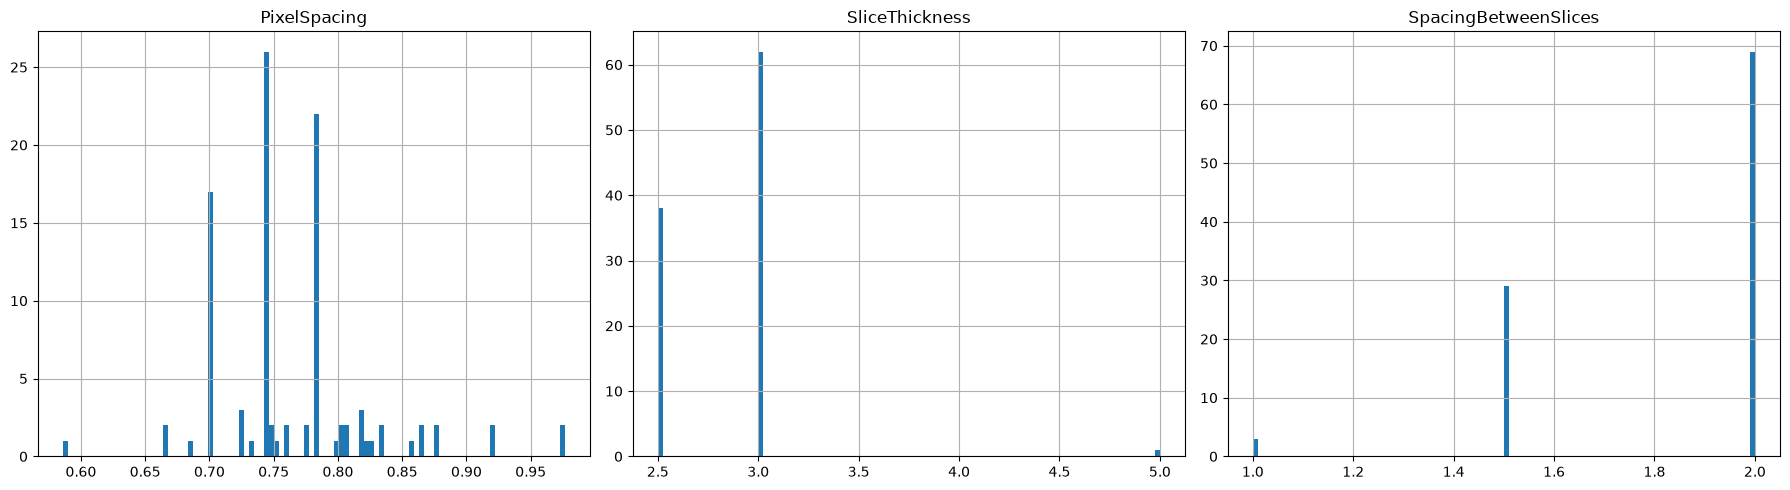

In [26]:
print(df.shape)
print(df["PixelSpacing"].describe())
print(df[df["PixelSpacing"] > 0.85]["PixelSpacing"].count())
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, ["PixelSpacing", "SliceThickness", "SpacingBetweenSlices"]):
    df[column].hist(bins=100, ax=ax)
    ax.set_title(column)

fig.tight_layout()

We could for example set the target resolution as 0.85 losing only 9 scans that way. The dataset readme file states that the scans were interpolated already so let's check the actual voxel spacing.

       SubjectID             size                    spacing  \
count        101              101                        101   
unique       101              101                         39   
top       Pat001  (256, 331, 220)  (0.742188, 0.742188, 2.0)   
freq           1                1                         18   

                                     origin  \
count                                   101   
unique                                  101   
top     (-183.199997, -110.390625, -439.25)   
freq                                      1   

                                            direction  
count                                             101  
unique                                              2  
top     (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)  
freq                                               97  


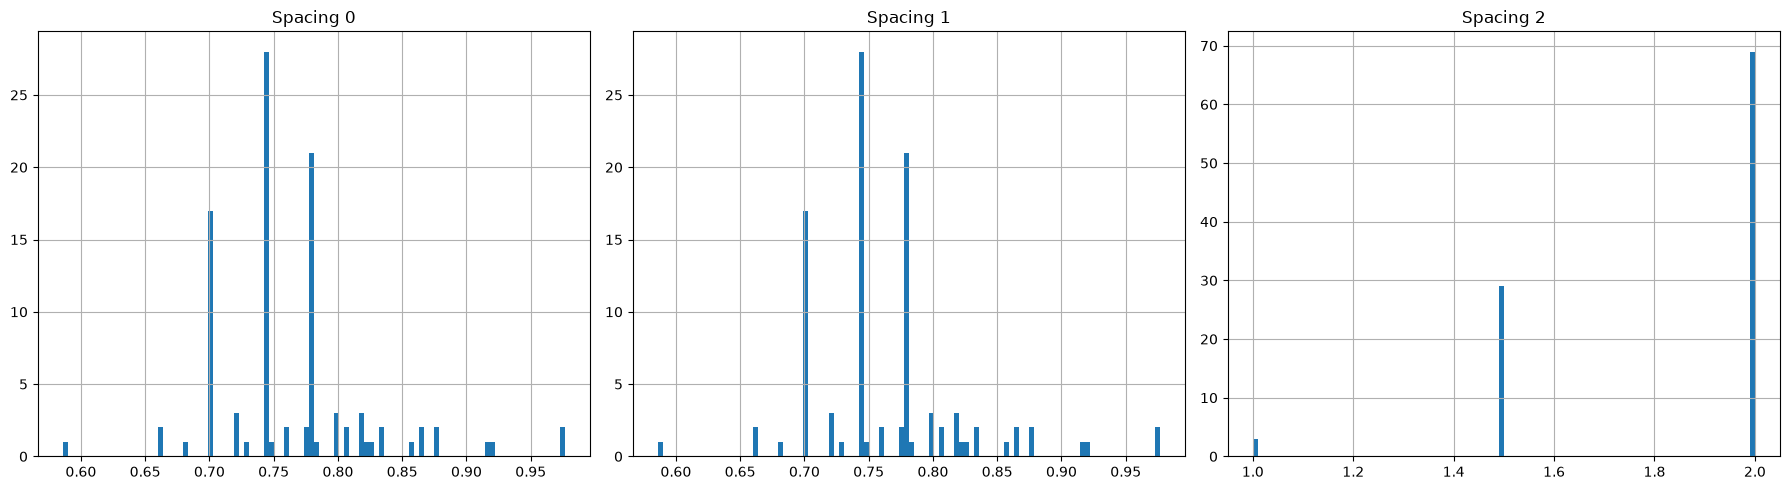

In [ ]:
nrrd_df=pandas.DataFrame(columns=["SubjectID","size","spacing","origin","direction"])

subjects = df.index.unique()
for subject in subjects:
    file=HFValid+"/Subjects/"+subject+"/"+subject+".nrrd"
    image = sitk.ReadImage(file)
    nrrd_df.loc[len(nrrd_df)] = [subject, image.GetSize(), image.GetSpacing(), image.GetOrigin(), image.GetDirection()]
  
print(nrrd_df.describe())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, dim in zip(axes, [0, 1, 2]):
    nrrd_df["spacing"].apply(lambda x: x[dim]).hist(bins=100, ax=ax)
    ax.set_title(f"Spacing {dim}")

fig.tight_layout()

Yup same thing. Let's run TotalSegmentator on the data and compare ASSD and HD95 to see how much can be gained from the superresolution.

In [6]:
nrrd_path = HFValid+"/Subjects/Pat001/Pat001.nrrd"
nifti_path = HFValid+"/Subjects/Pat001/Pat001.nii.gz"

ct=sitk.ReadImage(nrrd_path)
print("Size:", ct.GetSize())
print("Spacing:", ct.GetSpacing())
print("Origin:", ct.GetOrigin())
print("Direction:", ct.GetDirection())

sitk.WriteImage(ct, str(nifti_path), useCompression=True)

converted = sitk.ReadImage(str(nifti_path))

assert converted.GetSize() == ct.GetSize()
assert all(
    abs(a - b) < 1e-5
    for a, b in zip(converted.GetSpacing(), ct.GetSpacing())
)
print("Saved:", nifti_path)

Size: (256, 331, 220)
Spacing: (0.703125, 0.703125, 2.0)
Origin: (-183.199997, -110.390625, -439.25)
Direction: (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)
Saved: /home/loci/data/HFValid_Collection_v3/Subjects/Pat001/Pat001.nii.gz


In [ ]:
!TotalSegmentator -i /home/loci/data/HFValid_Collection_v3/Subjects/Pat001/Pat001.nii.gz -o /home/loci/data/HFValid/predictions/Pat001 --task total --device gpu


If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024

Resampling...
  Resampled in 0.40s
Predicting part 1 of 5 ...
100%|████████████████████████████████████████████| 6/6 [00:02<00:00,  2.02it/s]
Predicting part 2 of 5 ...
100%|████████████████████████████████████████████| 6/6 [00:00<00:00, 13.12it/s]
Predicting part 3 of 5 ...
100%|████████████████████████████████████████████| 6/6 [00:00<00:00, 10.70it/s]
Predicting part 4 of 5 ...
100%|████████████████████████████████████████████| 6/6 [00:00<00:00, 11.43it/s]
Predicting part 5 of 5 ...
100%|████████████████████████████████████████████| 6/6 [00:02<00:00,  2.14it/s]
  Predicted in 25.48s
Resampling...
  Resampled in 0.18s
Saving segmentations...
  Saved in 3.19s


In [ ]:
output_dir = "/home/loci/data/HFValid/predictions/Pat001"

for name in ("femur_left", "femur_right"):
    path = output_dir +"/"+ f"{name}.nii.gz"

    image = sitk.ReadImage(str(path))
    mask = sitk.GetArrayFromImage(image) > 0

    print(
        name,
        "shape:", mask.shape,
        "foreground voxels:", int(mask.sum()),
        "spacing:", image.GetSpacing(),
    )


femur_left shape: (220, 331, 256) foreground voxels: 0 spacing: (0.703125, 0.703125, 2.0)
femur_right shape: (220, 331, 256) foreground voxels: 443692 spacing: (0.703125, 0.703125, 2.0)


In [ ]:
import numpy as np
import SimpleITK as sitk


def same_geometry(a, b, atol=1e-5):
    return (
        a.GetSize() == b.GetSize()
        and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=atol)
        and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=atol)
        and np.allclose(a.GetDirection(), b.GetDirection(), atol=atol)
    )


ct_img = sitk.ReadImage(nrrd_path) 

ts_input = sitk.ReadImage(nifti_path)
pred_img = sitk.ReadImage(f"{output_dir}/femur_right.nii.gz")

print("NRRD and TotalSegmentator input have identical grids:",
      same_geometry(ct_img, ts_input))

print("TotalSegmentator input and prediction have identical grids:",
      same_geometry(ts_input, pred_img))

print("CT geometry:")
print(ct_img.GetSize(), ct_img.GetSpacing(),
      ct_img.GetOrigin(), ct_img.GetDirection())

print("Prediction geometry:")
print(pred_img.GetSize(), pred_img.GetSpacing(),
      pred_img.GetOrigin(), pred_img.GetDirection())

NRRD and TotalSegmentator input have identical grids: True
TotalSegmentator input and prediction have identical grids: True
CT geometry:
(256, 331, 220) (0.703125, 0.703125, 2.0) (-183.199997, -110.390625, -439.25) (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)
Prediction geometry:
(256, 331, 220) (0.703125, 0.703125, 2.0) (-183.1999969482422, -110.390625, -439.25) (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)


In [7]:
from util import stl_to_ct_mask, calculate_metrics
stl_path = HFValid+"/Subjects/Pat001/Pat001.stl"
output_dir = "/home/loci/data/HFValid/predictions/Pat001"
gt_image = sitk.ReadImage(nrrd_path)
image=None
pred_mask=None
for name in ("femur_left", "femur_right"):
    path = output_dir +"/"+ f"{name}.nii.gz"

    image = sitk.ReadImage(str(path))
    pred_mask = sitk.GetArrayFromImage(image) > 0
    
gt_mask = stl_to_ct_mask(stl_path, ct_image=gt_image)

print(calculate_metrics(gt_mask, pred_mask, spacing=gt_image.GetSpacing()))



/mnt/c/Users/Loci/Documents/tu2526/CT-SuperResolution/util.py:45: UserWarning: Some vertices are outside the CT image bounds. The resulting mask may be incomplete.
  warnings.warn(


(0.5333663939419091, 1.988737822087165, 0.9506841132660109)
